In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.impute import KNNImputer
from scipy import stats
from sklearn.preprocessing import StandardScaler

In [ ]:
df_path = "/content/drive/MyDrive/MBKM/Data/Data Aqi Pollutant dan Meteorologi Kelapa Gading.xlsx"
df = pd.read_excel(df_path)

In [ ]:
df.head(10)

,datetime,PM10,PM2.5,SO2,CO,O3,NO2,Suhu Udara,Radiasi Matahari,Suhu Titik Embun,Curah Hujan,Kelembaban Relatif,Kecepatan Angin
0,2022-01-01 00:00:00,65.6,87.6,47.2,12.2,37.4,23.4,25.94,0,23.29,0.42,83.18,3.18
1,2022-01-01 01:00:00,61.4,82.4,52.6,8.4,28.0,16.6,26.31,0,23.28,0.00,83.38,3.12
2,2022-01-01 02:00:00,73.0,89.0,50.4,16.6,59.2,31.8,28.53,0,23.49,0.00,83.97,3.10
3,2022-01-01 03:00:00,68.2,88.6,50.0,18.0,64.6,34.4,29.08,0,23.51,0.00,84.78,3.12
4,2022-01-01 04:00:00,62.6,80.8,49.6,15.0,55.2,32.0,29.77,0,23.35,0.00,85.51,3.12
5,2022-01-01 05:00:00,64.0,83.2,42.2,7.6,35.6,24.6,30.72,0,23.20,0.05,86.35,3.07
6,2022-01-01 06:00:00,55.0,73.6,51.6,8.2,27.8,19.8,31.03,89,23.20,0.00,86.57,2.92
7,2022-01-01 07:00:00,63.6,83.2,51.2,12.2,53.0,28.8,31.43,263,22.93,0.00,84.37,3.14
8,2022-01-01 08:00:00,67.2,85.8,49.8,10.8,66.8,23.6,30.49,385,23.11,0.00,80.24,3.36
9,2022-01-01 09:00:00,60.4,78.0,49.0,12.2,60.2,25.0,30.42,604,23.23,0.00,76.01,3.60


In [ ]:
df.dtypes

,0
datetime,datetime64[ns]
PM10,float64
PM2.5,float64
SO2,float64
CO,float64
O3,float64
NO2,float64
Suhu Udara,float64
Radiasi Matahari,int64
Suhu Titik Embun,float64


In [ ]:
df.isnull()

,datetime,PM10,PM2.5,SO2,CO,O3,NO2,Suhu Udara,Radiasi Matahari,Suhu Titik Embun,Curah Hujan,Kelembaban Relatif,Kecepatan Angin
0,False,False,False,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...
26299,False,False,False,False,False,False,False,False,False,False,False,False,False
26300,False,False,False,False,False,False,False,False,False,False,False,False,False
26301,False,False,False,False,False,False,False,False,False,False,False,False,False
26302,False,False,False,False,False,False,False,False,False,False,False,False,False


In [ ]:
df.isnull().sum()

,0
datetime,0
PM10,0
PM2.5,0
SO2,0
CO,0
O3,0
NO2,0
Suhu Udara,0
Radiasi Matahari,0
Suhu Titik Embun,0


In [ ]:
df['datetime'] = pd.to_datetime(df['datetime'], errors='coerce')
df_ts = df.set_index('datetime')
df_ts = df_ts.apply(pd.to_numeric, errors='coerce')

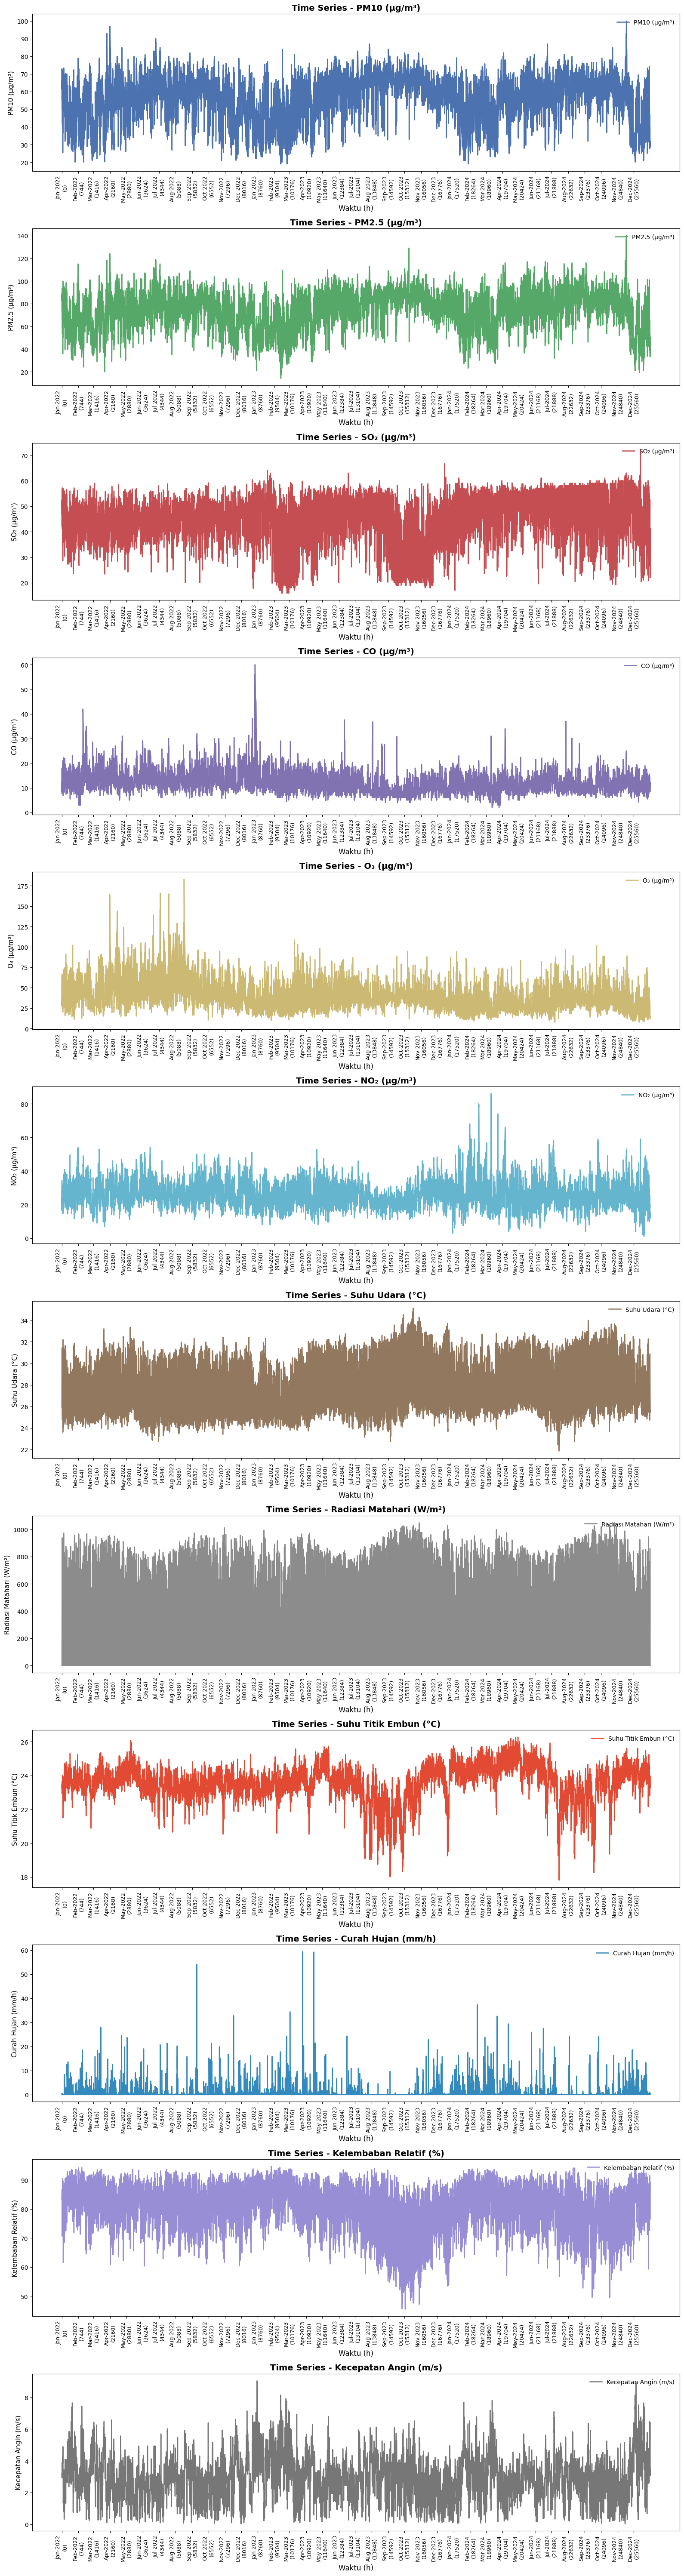

In [ ]:
if not isinstance(df_ts.index, pd.DatetimeIndex):
    df_ts.index = pd.to_datetime(df_ts.index)
df_ts = df_ts.sort_index()

hours = (df_ts.index - df_ts.index.min()) / pd.Timedelta(hours=1)

xticks = pd.date_range(start=df_ts.index.min().normalize(),
                       end=df_ts.index.max().normalize(), freq="MS")
xticks_hours = (xticks - df_ts.index.min()) / pd.Timedelta(hours=1)
labels = [f"{d.strftime('%b-%Y')}\n({int(h)})" for d, h in zip(xticks, xticks_hours)]

colors = [
    "#4C72B0", "#55A868", "#C44E52", "#8172B2", "#CCB974",
    "#64B5CD", "#937860", "#8C8C8C", "#E24A33", "#348ABD",
    "#988ED5", "#777777", "#FBC15E", "#8EBA42", "#FFB5B8"
]
if len(df_ts.columns) > len(colors):
    colors = (colors * (len(df_ts.columns) // len(colors) + 1))[:len(df_ts.columns)]

label_map = {
    'PM10': 'PM10 (µg/m³)',
    'PM2.5': 'PM2.5 (µg/m³)',
    'SO2': 'SO₂ (µg/m³)',
    'CO': 'CO (µg/m³)',
    'O3': 'O₃ (µg/m³)',
    'NO2': 'NO₂ (µg/m³)',
    'Suhu Udara': 'Suhu Udara (°C)',
    'Radiasi Matahari': 'Radiasi Matahari (W/m²)',
    'Suhu Titik Embun': 'Suhu Titik Embun (°C)',
    'Curah Hujan': 'Curah Hujan (mm/h)',
    'Kelembaban Relatif': 'Kelembaban Relatif (%)',
    'Kecepatan Angin': 'Kecepatan Angin (m/s)',
}

fig, axes = plt.subplots(
    nrows=len(df_ts.columns),
    figsize=(16, 5 * len(df_ts.columns)),
    sharex=False
)

if len(df_ts.columns) == 1:
    axes = [axes]

for ax, col, color in zip(axes, df_ts.columns, colors):
    ax.plot(hours, df_ts[col], color=color, linewidth=1.8, label=label_map.get(col, col))
    ax.set_title(f"Time Series - {label_map.get(col, col)}", fontsize=14, fontweight='bold')
    ax.set_ylabel(label_map.get(col, col), fontsize=11)
    ax.legend(loc="upper right", fontsize=10, frameon=False)
    ax.set_xticks(xticks_hours)
    ax.set_xticklabels(labels, rotation=90, ha="center", fontsize=9)

for ax in axes:
    ax.set_xlabel("Waktu (h)", fontsize=12)

plt.tight_layout()
plt.show()

In [ ]:
df_ts.describe().round(2)

,PM10,PM2.5,SO2,CO,O3,NO2,Suhu Udara,Radiasi Matahari,Suhu Titik Embun,Curah Hujan,Kelembaban Relatif,Kecepatan Angin
count,26304.00,26304.00,26304.00,26304.00,26304.00,26304.00,26304.00,26304.00,26304.00,26304.00,26304.00,26304.00
mean,56.28,74.35,45.24,12.10,38.88,25.92,27.53,223.82,23.55,0.59,81.46,2.86
std,13.62,17.52,10.76,4.62,19.50,8.47,2.27,297.68,1.02,2.06,8.34,1.27
min,19.00,14.00,16.00,2.00,8.00,1.00,21.85,0.00,17.81,0.00,45.50,0.04
25%,49.00,63.00,39.00,9.00,26.00,20.00,25.65,0.00,23.08,0.00,76.45,1.96
50%,59.00,76.20,47.00,11.40,35.00,25.00,27.05,14.00,23.66,0.00,83.42,2.77
75%,66.00,86.80,54.00,14.05,46.60,30.60,29.29,452.00,24.21,0.19,88.02,3.63
max,100.00,140.00,72.00,60.00,183.00,86.00,35.11,1047.00,26.26,59.33,94.68,9.03


In [ ]:
df.replace(['-', ''], np.nan, inplace=True)

for col in df.columns:
    if col != 'datetime':
        df[col] = pd.to_numeric(df[col], errors='coerce')

df_numeric = df.drop(columns=["datetime"])
datetime_col = df["datetime"]

In [ ]:
scaler = StandardScaler()
df_scaled = scaler.fit_transform(df_numeric)

In [ ]:
imputer = KNNImputer(n_neighbors=5)
df_scaled_imputed = imputer.fit_transform(df_scaled)

df_imputed = pd.DataFrame(scaler.inverse_transform(df_scaled_imputed), columns=df_numeric.columns)
df_imputed["datetime"] = datetime_col
df_imputed = df_imputed.set_index("datetime")

In [ ]:
df_imputed.head(10)

,PM10,PM2.5,SO2,CO,O3,NO2,Suhu Udara,Radiasi Matahari,Suhu Titik Embun,Curah Hujan,Kelembaban Relatif,Kecepatan Angin
datetime,,,,,,,,,,,,
2022-01-01 00:00:00,65.6,87.6,47.2,12.2,37.4,23.4,25.94,0.0,23.29,0.42,83.18,3.18
2022-01-01 01:00:00,61.4,82.4,52.6,8.4,28.0,16.6,26.31,0.0,23.28,0.00,83.38,3.12
2022-01-01 02:00:00,73.0,89.0,50.4,16.6,59.2,31.8,28.53,0.0,23.49,0.00,83.97,3.10
2022-01-01 03:00:00,68.2,88.6,50.0,18.0,64.6,34.4,29.08,0.0,23.51,0.00,84.78,3.12
2022-01-01 04:00:00,62.6,80.8,49.6,15.0,55.2,32.0,29.77,0.0,23.35,0.00,85.51,3.12
2022-01-01 05:00:00,64.0,83.2,42.2,7.6,35.6,24.6,30.72,0.0,23.20,0.05,86.35,3.07
2022-01-01 06:00:00,55.0,73.6,51.6,8.2,27.8,19.8,31.03,89.0,23.20,0.00,86.57,2.92
2022-01-01 07:00:00,63.6,83.2,51.2,12.2,53.0,28.8,31.43,263.0,22.93,0.00,84.37,3.14
2022-01-01 08:00:00,67.2,85.8,49.8,10.8,66.8,23.6,30.49,385.0,23.11,0.00,80.24,3.36


In [ ]:
df_imputed.to_csv("df_imputed.csv", index=False, float_format='%.2f')

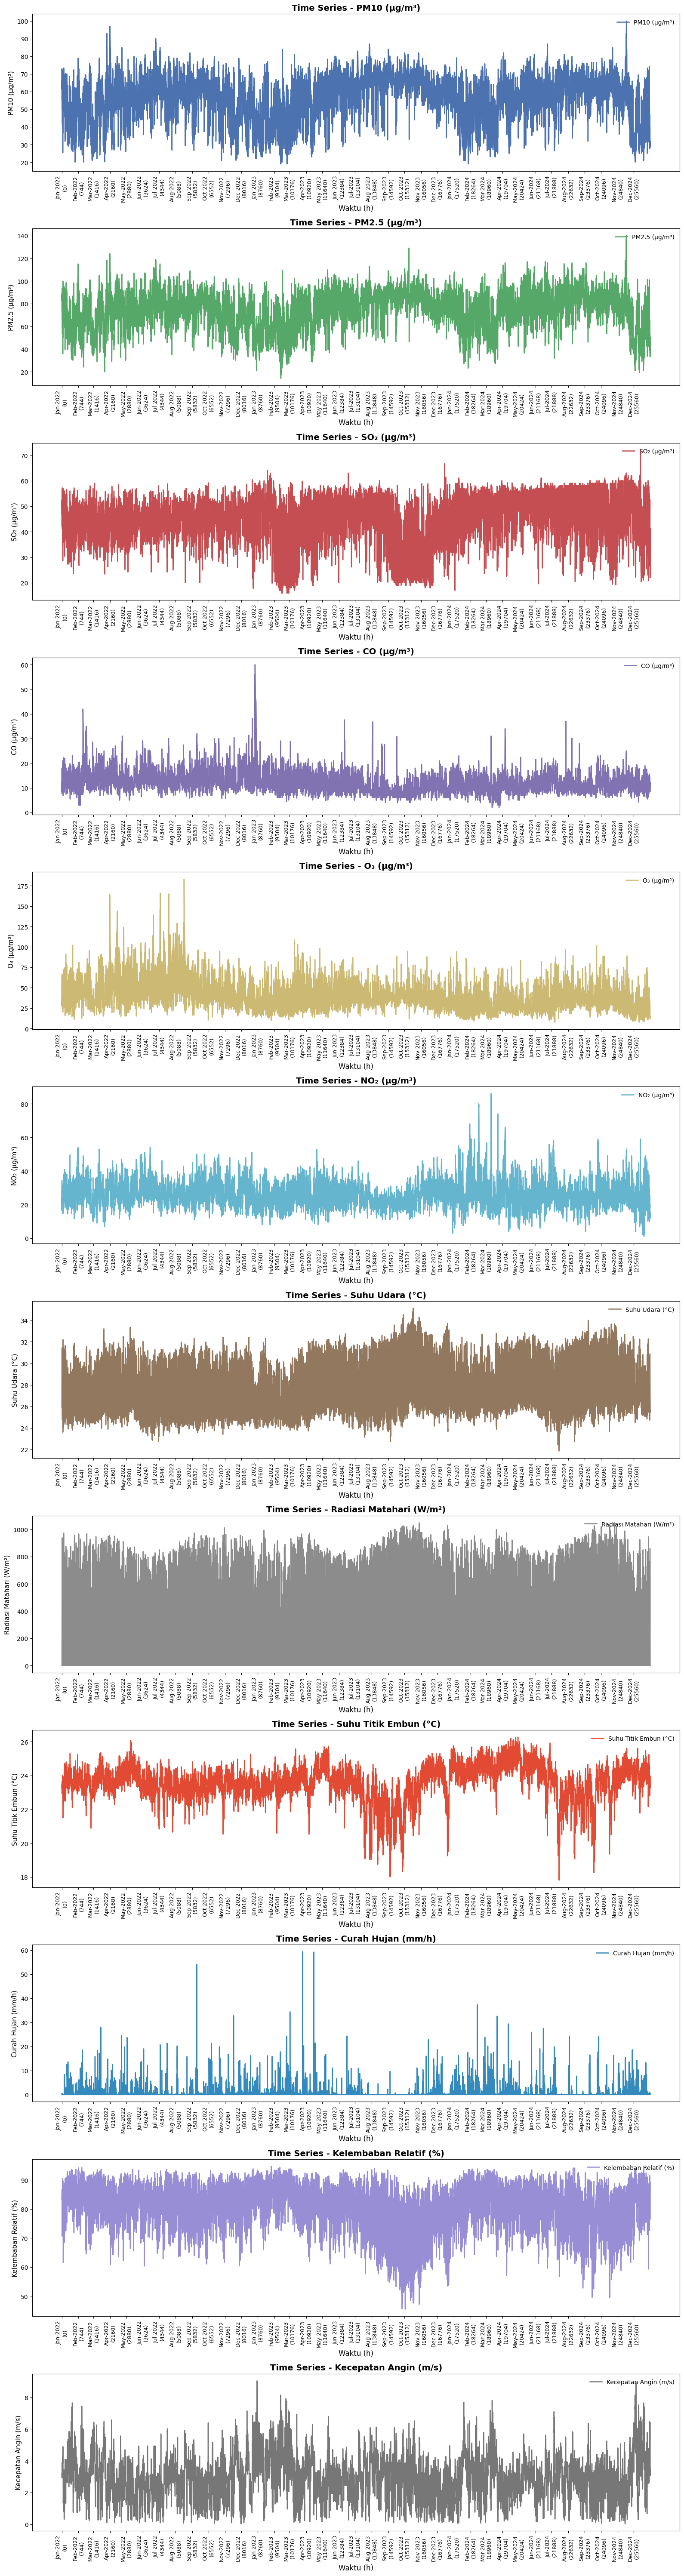

In [ ]:
if not isinstance(df_imputed.index, pd.DatetimeIndex):
    df_imputed.index = pd.to_datetime(df_imputed.index)
df_imputed = df_imputed.sort_index()

hours = (df_imputed.index - df_imputed.index.min()) / pd.Timedelta(hours=1)

xticks = pd.date_range(start=df_imputed.index.min().normalize(),
                       end=df_imputed.index.max().normalize(), freq="MS")
xticks_hours = (xticks - df_imputed.index.min()) / pd.Timedelta(hours=1)
labels = [f"{d.strftime('%b-%Y')}\n({int(h)})" for d, h in zip(xticks, xticks_hours)]

colors = [
    "#4C72B0", "#55A868", "#C44E52", "#8172B2", "#CCB974",
    "#64B5CD", "#937860", "#8C8C8C", "#E24A33", "#348ABD",
    "#988ED5", "#777777", "#FBC15E", "#8EBA42", "#FFB5B8"
]
if len(df_imputed.columns) > len(colors):
    colors = (colors * (len(df_imputed.columns) // len(colors) + 1))[:len(df_imputed.columns)]

label_map = {
    'PM10': 'PM10 (µg/m³)',
    'PM2.5': 'PM2.5 (µg/m³)',
    'SO2': 'SO₂ (µg/m³)',
    'CO': 'CO (µg/m³)',
    'O3': 'O₃ (µg/m³)',
    'NO2': 'NO₂ (µg/m³)',
    'Suhu Udara': 'Suhu Udara (°C)',
    'Radiasi Matahari': 'Radiasi Matahari (W/m²)',
    'Suhu Titik Embun': 'Suhu Titik Embun (°C)',
    'Curah Hujan': 'Curah Hujan (mm/h)',
    'Kelembaban Relatif': 'Kelembaban Relatif (%)',
    'Kecepatan Angin': 'Kecepatan Angin (m/s)',
}

fig, axes = plt.subplots(
    nrows=len(df_imputed.columns),
    figsize=(16, 5 * len(df_imputed.columns)),
    sharex=False
)

if len(df_imputed.columns) == 1:
    axes = [axes]

for ax, col, color in zip(axes, df_imputed.columns, colors):
    ax.plot(hours, df_imputed[col], color=color, linewidth=1.8, label=label_map.get(col, col))
    ax.set_title(f"Time Series - {label_map.get(col, col)}", fontsize=14, fontweight='bold')
    ax.set_ylabel(label_map.get(col, col), fontsize=11)
    ax.legend(loc="upper right", fontsize=10, frameon=False)
    ax.set_xticks(xticks_hours)
    ax.set_xticklabels(labels, rotation=90, ha="center", fontsize=9)

for ax in axes:
    ax.set_xlabel("Waktu (h)", fontsize=12)

plt.tight_layout()
plt.show()

In [ ]:
df_imputed.describe().round(2)

,PM10,PM2.5,SO2,CO,O3,NO2,Suhu Udara,Radiasi Matahari,Suhu Titik Embun,Curah Hujan,Kelembaban Relatif,Kecepatan Angin
count,26304.00,26304.00,26304.00,26304.00,26304.00,26304.00,26304.00,26304.00,26304.00,26304.00,26304.00,26304.00
mean,56.28,74.35,45.24,12.10,38.88,25.92,27.53,223.82,23.55,0.59,81.46,2.86
std,13.62,17.52,10.76,4.62,19.50,8.47,2.27,297.68,1.02,2.06,8.34,1.27
min,19.00,14.00,16.00,2.00,8.00,1.00,21.85,0.00,17.81,0.00,45.50,0.04
25%,49.00,63.00,39.00,9.00,26.00,20.00,25.65,0.00,23.08,0.00,76.45,1.96
50%,59.00,76.20,47.00,11.40,35.00,25.00,27.05,14.00,23.66,0.00,83.42,2.77
75%,66.00,86.80,54.00,14.05,46.60,30.60,29.29,452.00,24.21,0.19,88.02,3.63
max,100.00,140.00,72.00,60.00,183.00,86.00,35.11,1047.00,26.26,59.33,94.68,9.03


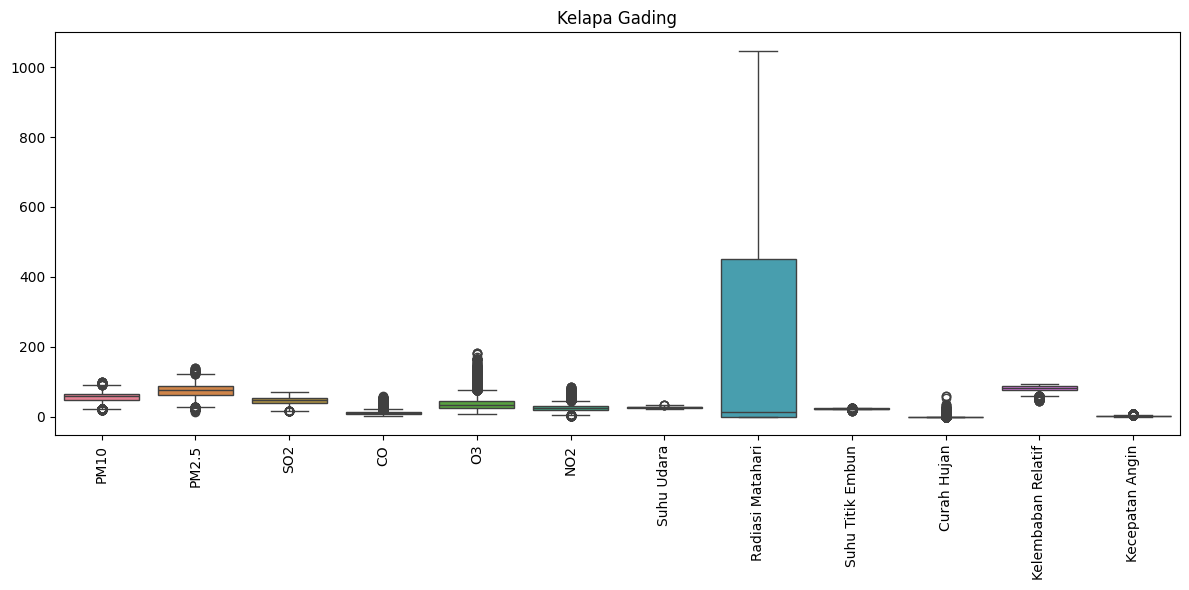

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
sns.boxplot(data=df_imputed)
plt.xticks(rotation=90)
plt.title("Kelapa Gading")
plt.tight_layout()
plt.show()
